Setup

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

from src.preprocessing import load_data, clean_data, split_data, build_preprocessor

data = clean_data(load_data())
X_train, X_test, y_train, y_test = split_data(data)
print(X_train.shape, y_train.mean().round(4))

(120000, 10) 0.0668


Define the models

In [2]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=5,
        class_weight="balanced_subsample", n_jobs=-1, random_state=42,
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(
        class_weight="balanced", random_state=42,
    ),
}

Cross-validate

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision"}

results = []
for name, model in models.items():
    pipe = Pipeline([("prep", build_preprocessor()), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    results.append({
        "model": name,
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "ROC-AUC std": scores["test_roc_auc"].std(),
        "PR-AUC": scores["test_pr_auc"].mean(),
    })
    print(f"{name} done")

results_df = pd.DataFrame(results).round(4).sort_values("ROC-AUC", ascending=False)
results_df

Logistic Regression done
Random Forest done
Gradient Boosting done


,model,ROC-AUC,ROC-AUC std,PR-AUC
2,Gradient Boosting,0.8633,0.0026,0.3937
1,Random Forest,0.8555,0.0024,0.3798
0,Logistic Regression,0.8546,0.0044,0.3806


SMOTE vs class weights

In [4]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

smote_models = {
    "LogReg + SMOTE": LogisticRegression(max_iter=1000),
    "GradBoost + SMOTE": HistGradientBoostingClassifier(random_state=42),
}

smote_results = []
for name, model in smote_models.items():
    pipe = ImbPipeline([
        ("prep", build_preprocessor()),
        ("smote", SMOTE(random_state=42)),
        ("model", model),
    ])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    smote_results.append({
        "model": name,
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "ROC-AUC std": scores["test_roc_auc"].std(),
        "PR-AUC": scores["test_pr_auc"].mean(),
    })
    print(f"{name} done")

pd.concat([results_df, pd.DataFrame(smote_results).round(4)], ignore_index=True).sort_values("ROC-AUC", ascending=False)

LogReg + SMOTE done
GradBoost + SMOTE done


,model,ROC-AUC,ROC-AUC std,PR-AUC
0,Gradient Boosting,0.8633,0.0026,0.3937
1,Random Forest,0.8555,0.0024,0.3798
2,Logistic Regression,0.8546,0.0044,0.3806
3,LogReg + SMOTE,0.8537,0.0044,0.3795
4,GradBoost + SMOTE,0.8535,0.0038,0.3613


Tune Gradient Boosting:

In [5]:
from sklearn.model_selection import RandomizedSearchCV

pipe = Pipeline([
    ("prep", build_preprocessor()),
    ("model", HistGradientBoostingClassifier(class_weight="balanced", random_state=42)),
])

param_dist = {
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__max_iter": [100, 200, 300],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [20, 50, 100],
    "model__l2_regularization": [0, 0.1, 1.0],
}

search = RandomizedSearchCV(
    pipe, param_dist, n_iter=15, scoring="roc_auc",
    cv=cv, random_state=42, n_jobs=-1, verbose=1,
)
search.fit(X_train, y_train)
print("Best CV ROC-AUC:", round(search.best_score_, 4))
print(search.best_params_)

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best CV ROC-AUC: 0.8644
{'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 15, 'model__max_iter': 300, 'model__learning_rate': 0.05, 'model__l2_regularization': 0.1}


**Result:** Class weights beat SMOTE for ranking (ROC-AUC 0.8633 vs 0.8535), and tuning added
only 0.001. But class weights inflate the predicted probabilities (Brier score 0.143), so for
the final model I retrained without weights. Ranking stayed the same (ROC-AUC 0.868) and the
probabilities became well calibrated (Brier 0.049).

Test metrics

In [6]:
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
import matplotlib.pyplot as plt

best_model = search.best_estimator_   # already refit on the full training set
proba = best_model.predict_proba(X_test)[:, 1]

print("Test ROC-AUC:", round(roc_auc_score(y_test, proba), 4))
print("Test PR-AUC: ", round(average_precision_score(y_test, proba), 4))
print("No-skill PR-AUC baseline:", round(y_test.mean(), 4))

Test ROC-AUC: 0.8683
Test PR-AUC:  0.4067
No-skill PR-AUC baseline: 0.0668


ROC and precision-recall curves

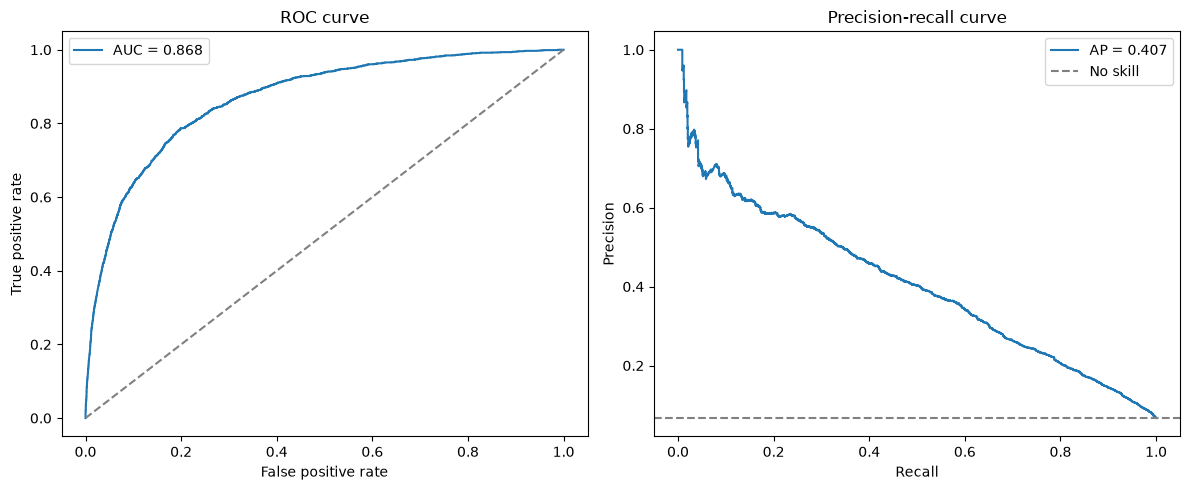

In [7]:
fpr, tpr, _ = roc_curve(y_test, proba)
prec, rec, _ = precision_recall_curve(y_test, proba)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, proba):.3f}")
ax[0].plot([0, 1], [0, 1], "--", color="gray")
ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve")
ax[0].legend()

ax[1].plot(rec, prec, label=f"AP = {average_precision_score(y_test, proba):.3f}")
ax[1].axhline(y_test.mean(), ls="--", color="gray", label="No skill")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve")
ax[1].legend()

plt.tight_layout()
plt.savefig("../reports/roc_pr_curves.png", dpi=150)
plt.show()

Threshold analysis

In [8]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    pred = proba >= t
    tp = (pred & (y_test == 1)).sum()
    rows.append({
        "threshold": t,
        "flagged %": pred.mean() * 100,
        "precision": tp / max(pred.sum(), 1),
        "recall": tp / (y_test == 1).sum(),
    })
pd.DataFrame(rows).round(3)

,threshold,flagged %,precision,recall
0,0.3,41.107,0.146,0.897
1,0.4,32.143,0.176,0.846
2,0.5,24.417,0.215,0.787
3,0.6,16.830,0.272,0.684
4,0.7,11.573,0.345,0.597
5,0.8,7.900,0.410,0.484


These thresholds are for the class-weighted model, whose scores run high. See the calibration table below for the final model.

Save the model

In [9]:
import joblib
joblib.dump(best_model, "../models/loan_default_model_weighted.joblib")

['../models/loan_default_model_weighted.joblib']

Retrain

In [10]:
from sklearn.metrics import brier_score_loss

final = Pipeline([
    ("prep", build_preprocessor()),
    ("model", HistGradientBoostingClassifier(random_state=42)),   # no class_weight
])
final.set_params(**search.best_params_)
final.fit(X_train, y_train)

p_new = final.predict_proba(X_test)[:, 1]
print("Test ROC-AUC:", round(roc_auc_score(y_test, p_new), 4))
print("Test PR-AUC: ", round(average_precision_score(y_test, p_new), 4))
print("Brier score (lower = better calibrated):")
print("  class-weighted model:", round(brier_score_loss(y_test, proba), 4))
print("  unweighted model:    ", round(brier_score_loss(y_test, p_new), 4))

Test ROC-AUC: 0.8678
Test PR-AUC:  0.409
Brier score (lower = better calibrated):
  class-weighted model: 0.1426
  unweighted model:     0.0487


Calibration table

In [11]:
cal = (pd.DataFrame({"p": p_new, "y": y_test.values})
         .groupby(pd.qcut(p_new, 10, duplicates="drop"), observed=True)
         .agg(avg_predicted=("p", "mean"), actual_rate=("y", "mean"), borrowers=("y", "size"))
         .round(3))
cal

,avg_predicted,actual_rate,borrowers
"(0.00328, 0.00695]",0.006,0.003,3001
"(0.00695, 0.00915]",0.008,0.006,2999
"(0.00915, 0.0117]",0.010,0.009,3000
"(0.0117, 0.0157]",0.014,0.011,3000
"(0.0157, 0.0223]",0.019,0.018,3000
"(0.0223, 0.0333]",0.027,0.026,3000
"(0.0333, 0.0515]",0.042,0.035,3000
"(0.0515, 0.0838]",0.066,0.071,3000
"(0.0838, 0.168]",0.115,0.119,3000
"(0.168, 0.867]",0.361,0.369,3000


In [12]:
rows = []
for t in [0.05, 0.10, 0.15, 0.20, 0.30]:
    pred = p_new >= t
    tp = (pred & (y_test == 1)).sum()
    rows.append({
        "threshold": t,
        "flagged %": pred.mean() * 100,
        "precision": tp / max(pred.sum(), 1),
        "recall": tp / (y_test == 1).sum(),
    })
pd.DataFrame(rows).round(3)

,threshold,flagged %,precision,recall
0,0.05,30.657,0.184,0.842
1,0.10,16.727,0.273,0.683
2,0.15,11.060,0.352,0.583
3,0.20,8.640,0.394,0.509
4,0.30,5.723,0.469,0.402


Save the final model

In [13]:
joblib.dump(final, "../models/loan_default_model.joblib")

['../models/loan_default_model.joblib']